# Hot Potato Effect Within a Single Tick
## Empirical Investigation Using NASDAQ ITCH 5.0 Order Book Data

**SMMG Research** — Pankaj J. · Bhavik P. · David M.

---

This notebook documents our empirical investigation of the hot potato mechanism
at the intra-tick level using NASDAQ TotalView-ITCH 5.0 full order book data.

**Dataset:** SPY — January 30, 2020 — Full Trading Day (~423 million ITCH packets)
**Parser:** Custom Go-based ITCH 5.0 binary parser → Apache Parquet pipeline

### Contents
1. Dataset overview and pipeline
2. Are odd-lot executions unusual? *(Initial uncertainity)*
3. Odd-lot execution patterns — time of day, quantities, depth
4. Fill-flip detection — methodology, fingerprint filtering, results
5. Time delta analysis — how fast are the flips?
6. Interpretation and significance
7. Further research directions

In [17]:
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams['figure.figsize'] = (13, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['font.size'] = 11

df  = pl.read_parquet('executions.parquet')
odd = df.filter(pl.col('is_odd_lot') == True)
rnd = df.filter(pl.col('is_odd_lot') == False)

print('=' * 55)
print('  DATASET — SPY, January 30 2020, Full Day')
print('=' * 55)
print(f'  Total executions     : {len(df):>10,}')
print(f'  Round-lot            : {len(rnd):>10,}  ({len(rnd)/len(df)*100:.1f}%)')
print(f'  Odd-lot              : {len(odd):>10,}  ({len(odd)/len(df)*100:.1f}%)')
print(f'  Unique odd-lot qtys  : {odd["shares_executed"].n_unique():>10,}')
print('=' * 55)

import os
os.makedirs('images', exist_ok=True)


  DATASET — SPY, January 30 2020, Full Day
  Total executions     :     80,910
  Round-lot            :     50,245  (62.1%)
  Odd-lot              :     30,665  (37.9%)
  Unique odd-lot qtys  :        914


---
## 1. Pipeline Description

We built a custom Go parser for NASDAQ ITCH 5.0 binary data. The parser maintains
a **live in-memory order book** and for every execution event writes one enriched
row to Apache Parquet:

| Column | Description |
|--------|-------------|
| `timestamp_ns` | Nanoseconds since midnight — full nanosecond resolution |
| `side` | Side of the **resting** order (B = bid, S = ask) |
| `price` | Execution price in dollars |
| `shares_executed` | Shares consumed in this execution |
| `is_odd_lot` | True if quantity not divisible by 100 |
| `shares_remaining_at_level_after_fill` | Depth still resting at this price level after this fill |
| `num_orders_remaining_at_level_after_fill` | Orders still resting at this level |
| `level_formed_at_ns` | When the first order arrived at this price level |

**Processing stats:** 423 million ITCH packets → 80,910 SPY execution rows → ~40-45 min runtime.

---
## 2. Are Odd-Lot Executions Unusual?

> *Question: "Are quantities like 207, 305 — odd lots — unusual?"*

**Answer: No. Odd-lot executions are not unusual at all.**

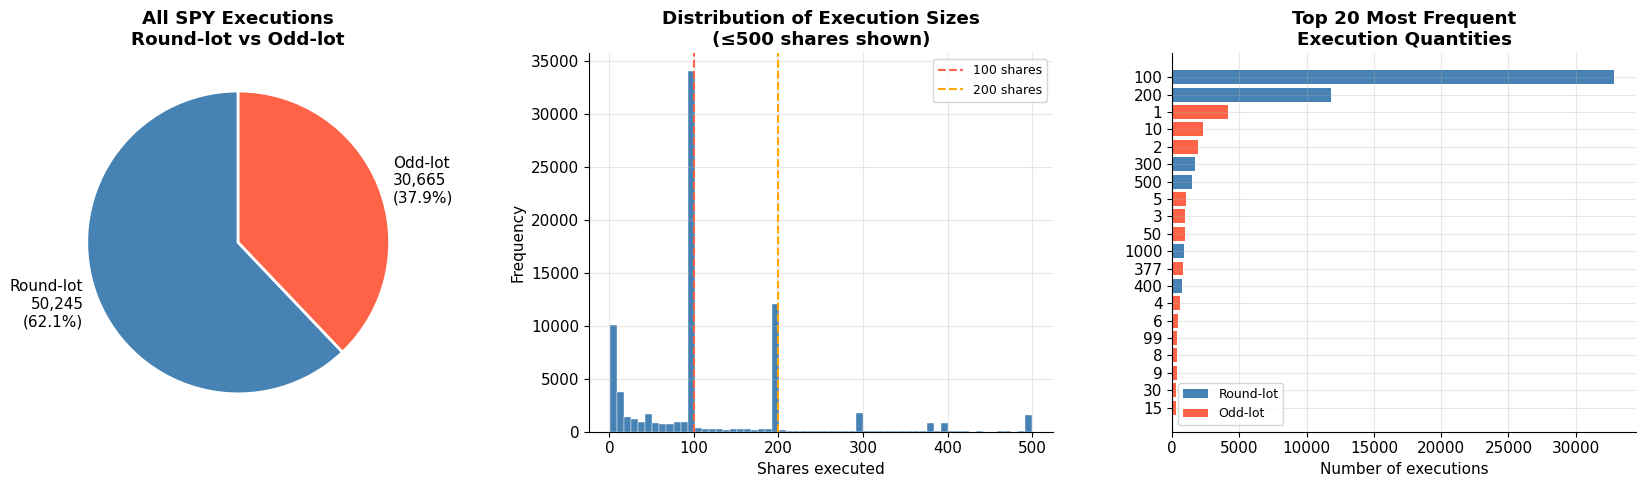

Key finding: 37.9% of all SPY executions were odd-lot.
Odd-lot executions are not unusual — they are a structural feature of modern markets.


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sizes  = [len(rnd), len(odd)]
labels = [f'Round-lot\n{len(rnd):,}\n({len(rnd)/len(df)*100:.1f}%)',
          f'Odd-lot\n{len(odd):,}\n({len(odd)/len(df)*100:.1f}%)']
axes[0].pie(sizes, labels=labels, colors=['steelblue','tomato'],
            startangle=90, wedgeprops={'edgecolor':'white','linewidth':2})
axes[0].set_title('All SPY Executions\nRound-lot vs Odd-lot', fontweight='bold')

shares = df['shares_executed'].to_numpy()
axes[1].hist(shares[shares <= 500], bins=60, color='steelblue', edgecolor='white', linewidth=0.3)
axes[1].axvline(100, color='tomato', linestyle='--', lw=1.5, label='100 shares')
axes[1].axvline(200, color='orange', linestyle='--', lw=1.5, label='200 shares')
axes[1].set_xlabel('Shares executed'); axes[1].set_ylabel('Frequency')
axes[1].set_title('Distribution of Execution Sizes\n(≤500 shares shown)', fontweight='bold')
axes[1].legend(fontsize=9)

qty_freq = (df.group_by('shares_executed')
              .agg(pl.len().alias('count'))
              .sort('count', descending=True).head(20))
is_odd_bar = [q % 100 != 0 for q in qty_freq['shares_executed'].to_list()]
bar_colors = ['tomato' if o else 'steelblue' for o in is_odd_bar]
axes[2].barh([str(q) for q in qty_freq['shares_executed'].to_list()],
             qty_freq['count'].to_list(), color=bar_colors)
axes[2].set_xlabel('Number of executions')
axes[2].set_title('Top 20 Most Frequent\nExecution Quantities', fontweight='bold')
axes[2].invert_yaxis()
legend_els = [mpatches.Patch(facecolor='steelblue', label='Round-lot'),
              mpatches.Patch(facecolor='tomato', label='Odd-lot')]
axes[2].legend(handles=legend_els, fontsize=9)
plt.tight_layout()
plt.savefig('images/fig1_oddlot_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Key finding: {len(odd)/len(df)*100:.1f}% of all SPY executions were odd-lot.')
print('Odd-lot executions are not unusual — they are a structural feature of modern markets.')

---
## 3. Odd-Lot Execution Patterns

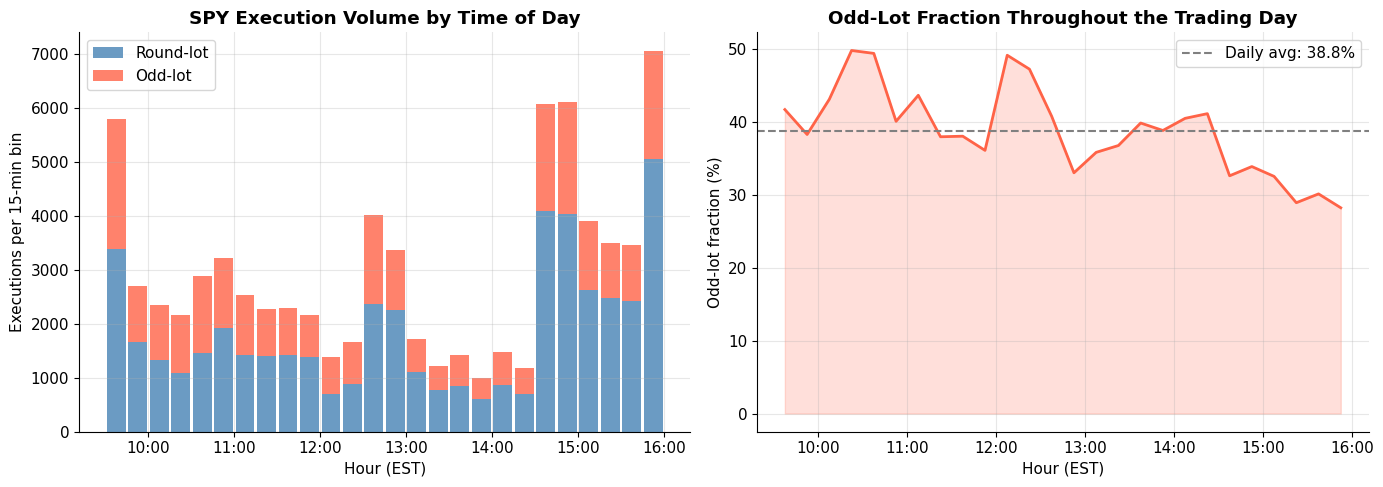

In [19]:
df_h = df.with_columns((pl.col('timestamp_ns') / 1e9 / 3600).alias('hour'))
odd_h = df_h.filter(pl.col('is_odd_lot') == True)['hour'].to_numpy()
rnd_h = df_h.filter(pl.col('is_odd_lot') == False)['hour'].to_numpy()
bins  = np.arange(9.5, 16.1, 0.25)
odd_cnt, _ = np.histogram(odd_h, bins=bins)
rnd_cnt, _ = np.histogram(rnd_h, bins=bins)
bin_c = (bins[:-1] + bins[1:]) / 2
total_cnt = odd_cnt + rnd_cnt
odd_frac  = np.where(total_cnt > 0, odd_cnt / total_cnt * 100, 0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(bin_c, rnd_cnt, width=0.22, label='Round-lot', color='steelblue', alpha=0.8)
axes[0].bar(bin_c, odd_cnt, width=0.22, bottom=rnd_cnt, label='Odd-lot', color='tomato', alpha=0.8)
axes[0].set_xlabel('Hour (EST)'); axes[0].set_ylabel('Executions per 15-min bin')
axes[0].set_title('SPY Execution Volume by Time of Day', fontweight='bold')
axes[0].set_xticks(np.arange(10, 17))
axes[0].set_xticklabels([f'{h}:00' for h in range(10, 17)])
axes[0].legend()

axes[1].plot(bin_c, odd_frac, color='tomato', linewidth=2)
axes[1].fill_between(bin_c, odd_frac, alpha=0.2, color='tomato')
axes[1].axhline(odd_frac.mean(), color='grey', linestyle='--',
                label=f'Daily avg: {odd_frac.mean():.1f}%')
axes[1].set_xlabel('Hour (EST)'); axes[1].set_ylabel('Odd-lot fraction (%)')
axes[1].set_title('Odd-Lot Fraction Throughout the Trading Day', fontweight='bold')
axes[1].set_xticks(np.arange(10, 17))
axes[1].set_xticklabels([f'{h}:00' for h in range(10, 17)])
axes[1].legend()
plt.tight_layout()
plt.savefig('images/fig2_time_of_day.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 4. Fill-Flip Detection

### 4.1 The Hot Potato Mechanism

From Our documented case study (section 2 of the draft paper):

1. Agent rests a **limit sell** at price P — passive, waiting in the ask queue
2. An incoming market buy sweeps the queue in FIFO order — Agent's order is filled — Agent is now **short**
3. Agent immediately flips with a **market buy** to close the short — hitting the **same ask queue at the same price P**
4. This consumes the agent who was **directly behind** in the FIFO queue — the hot potato is passed

In ITCH data, **both events appear as executions on resting sell orders (side = S)**:
- Event 1: Agent's resting sell gets consumed → `side=S, price=P, qty=Q`
- Event 2: Agent's market buy hits the next resting sell → `side=S, price=P, qty=Q`

Same side, same price, same quantity, within milliseconds.

### 4.2 The Odd-Lot Fingerprint

The quantity Q is the identification key. Our paper explains why:

> *"Odd-lot quantities such as 107 are comparatively rare and are therefore unlikely
> to reflect deliberate trade sizing. Instead, their appearance strongly indicates
> a mechanical origin, arising from execution sequencing rather than strategic intent."*

The 107-share residual is generated mechanically by FIFO queue depletion — not chosen.
This makes it a distinctive fingerprint for tracing the fill-flip sequence through data.

### 4.3 The Noise Problem and How We Handle It

Not all odd-lot quantities are equally distinctive. We found that:
- **Quantity = 1** appears 4,170 times — fractional share routing noise
- **Quantity = 50** appears 935 times — deliberate half-lot algorithmic trading
- **Quantity = 377** appears 829 times — a repeating algorithmic strategy

These quantities appear many times at the same price level and would generate
false matches (--regarding fill flip identification). They are not mechanically generated residuals.

**Our fingerprint filter:** We retain only quantities that appear **at most 3 times
at any single price+side level** across the entire trading day.
This gives us 841 genuinely distinctive fingerprint quantities covering 8,343 fills —
quantities that are rare enough that two occurrences at the same price within 1ms
cannot plausibly be coincidental.

In [20]:
# ── Strict set: quantities >= 50 shares, appear at most 3x at any price+side
# (original criterion — conservative, very clean fingerprints)
odd_50 = odd.filter(pl.col('shares_executed') >= 50)

level_max = (odd_50.group_by(['shares_executed', 'price', 'side'])
             .agg(pl.len().alias('n'))
             .group_by('shares_executed')
             .agg(pl.col('n').max().alias('max_at_any_level'))
             .filter(pl.col('max_at_any_level') <= 3))

fingerprint_qtys_strict = level_max['shares_executed'].to_list()
odd_fp_strict = odd_50.filter(pl.col('shares_executed').is_in(fingerprint_qtys_strict))

print('── STRICT fingerprint set ──────────────────────────────')
print(f'  Base: odd-lot fills with qty >= 50 shares : {len(odd_50):,}')
print(f'  Fingerprint quantities (appear <=3x at any level): {len(fingerprint_qtys_strict):,}')
print(f'  Fills in strict set                        : {len(odd_fp_strict):,}')

# ── Lax set: drop qty < 10 and exact multiples of 10 (new suggestion)
# No upper bound on how many times a quantity can appear at a level.
# This captures more potential flips including chains (hot potato passed multiple times).
odd_lax = odd.filter(
    (pl.col('shares_executed') >= 10) &
    (pl.col('shares_executed') % 10 != 0)
)

print()
print('── LAX fingerprint set (new criterion) ─────────────')
print(f'  Drop qty < 10 and exact multiples of 10')
print(f'  Fills in lax set                           : {len(odd_lax):,}')
print()
print('Examples of quantities excluded by lax filter (multiples of 10):')
excluded_lax = odd.filter(
    (pl.col('shares_executed') >= 10) &
    (pl.col('shares_executed') % 10 == 0)
)
print(excluded_lax.group_by('shares_executed').agg(pl.len().alias('n'))
      .sort('n', descending=True).head(8))


── STRICT fingerprint set ──────────────────────────────
  Base: odd-lot fills with qty >= 50 shares : 12,553
  Fingerprint quantities (appear <=3x at any level): 841
  Fills in strict set                        : 8,343

── LAX fingerprint set (new criterion) ─────────────
  Drop qty < 10 and exact multiples of 10
  Fills in lax set                           : 15,174

Examples of quantities excluded by lax filter (multiples of 10):
shape: (8, 2)
┌─────────────────┬──────┐
│ shares_executed ┆ n    │
│ ---             ┆ ---  │
│ i32             ┆ u32  │
╞═════════════════╪══════╡
│ 10              ┆ 2332 │
│ 50              ┆ 935  │
│ 30              ┆ 304  │
│ 20              ┆ 240  │
│ 90              ┆ 239  │
│ 40              ┆ 213  │
│ 60              ┆ 156  │
│ 80              ┆ 133  │
└─────────────────┴──────┘


In [21]:
def detect_fill_flip(fp_df, window_ns):
    """
    Detect fill-flip pairs.
    Both events: same stock, same price, same side, same quantity,
    different match numbers, flip after initiator, within time window.
    """
    initiator = fp_df.select([
        pl.col('timestamp_ns').alias('init_ts'),
        pl.col('stock').alias('init_stock'),
        pl.col('side').alias('init_side'),
        pl.col('price').alias('init_price'),
        pl.col('shares_executed').alias('init_shares'),
        pl.col('match_number').alias('init_match'),
        pl.col('shares_remaining_at_level_after_fill').alias('init_depth_remaining'),
        pl.col('num_orders_remaining_at_level_after_fill').alias('init_orders_remaining'),
    ])
    flip = fp_df.select([
        pl.col('timestamp_ns').alias('flip_ts'),
        pl.col('stock').alias('flip_stock'),
        pl.col('side').alias('flip_side'),
        pl.col('price').alias('flip_price'),
        pl.col('shares_executed').alias('flip_shares'),
        pl.col('match_number').alias('flip_match'),
    ])
    return (
        initiator
        .join(flip,
              left_on =['init_stock','init_price','init_shares','init_side'],
              right_on=['flip_stock','flip_price','flip_shares','flip_side'],
              how='inner')
        .filter(pl.col('init_match') != pl.col('flip_match'))
        .filter(pl.col('flip_ts') > pl.col('init_ts'))
        .filter((pl.col('flip_ts') - pl.col('init_ts')) <= window_ns)
        .with_columns((pl.col('flip_ts') - pl.col('init_ts')).alias('time_delta_ns'))
        .sort('time_delta_ns')
        .unique(subset=['init_match'], keep='first')
    )

windows = [1_000_000, 5_000_000, 10_000_000, 50_000_000]
results_strict = {}
results_lax    = {}
pair_dfs_strict = {}
pair_dfs_lax    = {}

print('── STRICT set results ──────────────────────────────────')
for w in windows:
    p = detect_fill_flip(odd_fp_strict, w)
    results_strict[w] = len(p)
    pair_dfs_strict[w] = p
    base = len(odd_fp_strict)
    print(f'  Window {w/1e6:>4.0f}ms → {len(p):>4} pairs  (hit rate: {len(p)/base*100:.2f}%)')

print()
print('── LAX set results (new criterion) ─────────────────')
for w in windows:
    p = detect_fill_flip(odd_lax, w)
    results_lax[w] = len(p)
    pair_dfs_lax[w] = p
    base = len(odd_lax)
    print(f'  Window {w/1e6:>4.0f}ms → {len(p):>4} pairs  (hit rate: {len(p)/base*100:.2f}%)')

pairs_1ms_strict = pair_dfs_strict[1_000_000]
pairs_1ms_lax    = pair_dfs_lax[1_000_000]

td_strict = pairs_1ms_strict['time_delta_ns'].to_numpy()
td_lax    = pairs_1ms_lax['time_delta_ns'].to_numpy()

print()
print('── 1ms time delta — strict ─────────────────────────────')
print(f'  Min    : {td_strict.min():,} ns = {td_strict.min()/1000:.1f} µs')
print(f'  Median : {int(np.median(td_strict)):,} ns = {np.median(td_strict)/1000:.1f} µs')
print(f'  < 100µs: {(td_strict < 100_000).sum()} pairs ({(td_strict < 100_000).sum()/len(td_strict)*100:.1f}%)')
print(f'  < 500µs: {(td_strict < 500_000).sum()} pairs ({(td_strict < 500_000).sum()/len(td_strict)*100:.1f}%)')

print()
print('── 1ms time delta — lax ────────────────────────────────')
print(f'  Min    : {td_lax.min():,} ns = {td_lax.min()/1000:.1f} µs')
print(f'  Median : {int(np.median(td_lax)):,} ns = {np.median(td_lax)/1000:.1f} µs')
print(f'  < 100µs: {(td_lax < 100_000).sum()} pairs ({(td_lax < 100_000).sum()/len(td_lax)*100:.1f}%)')
print(f'  < 500µs: {(td_lax < 500_000).sum()} pairs ({(td_lax < 500_000).sum()/len(td_lax)*100:.1f}%)')


── STRICT set results ──────────────────────────────────
  Window    1ms →  134 pairs  (hit rate: 1.61%)
  Window    5ms →  154 pairs  (hit rate: 1.85%)
  Window   10ms →  166 pairs  (hit rate: 1.99%)
  Window   50ms →  207 pairs  (hit rate: 2.48%)

── LAX set results (new criterion) ─────────────────
  Window    1ms →  400 pairs  (hit rate: 2.64%)
  Window    5ms →  515 pairs  (hit rate: 3.39%)
  Window   10ms →  571 pairs  (hit rate: 3.76%)
  Window   50ms →  679 pairs  (hit rate: 4.47%)

── 1ms time delta — strict ─────────────────────────────
  Min    : 623 ns = 0.6 µs
  Median : 106,308 ns = 106.3 µs
  < 100µs: 64 pairs (47.8%)
  < 500µs: 121 pairs (90.3%)

── 1ms time delta — lax ────────────────────────────────
  Min    : 561 ns = 0.6 µs
  Median : 106,769 ns = 106.8 µs
  < 100µs: 190 pairs (47.5%)
  < 500µs: 352 pairs (88.0%)


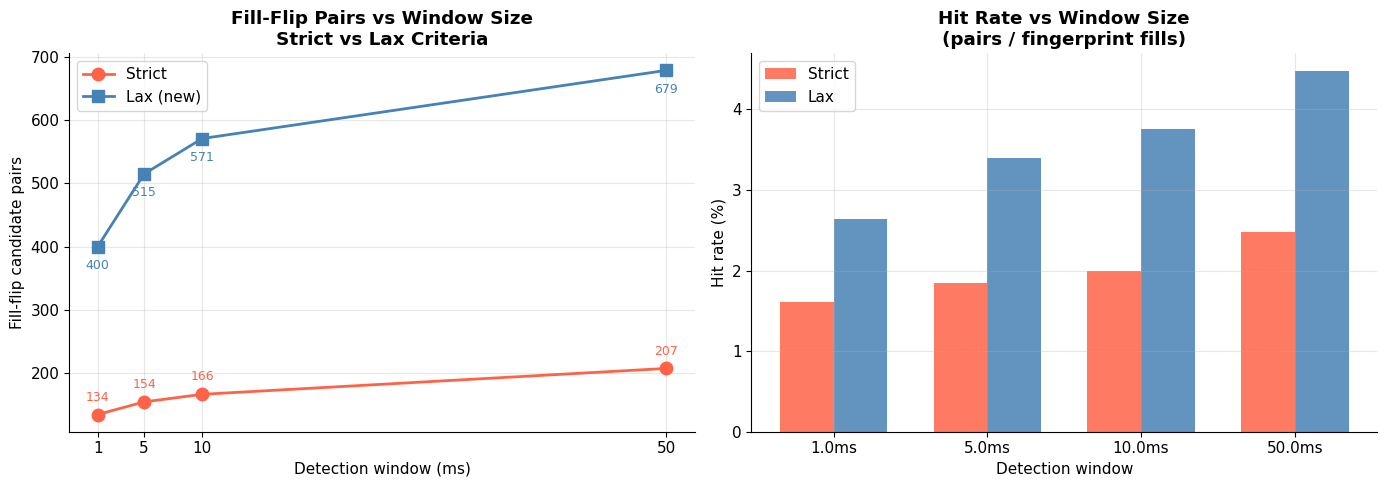

Strict: 50x window expansion → 1.54x more pairs
  → 65% of all detectable pairs occur within the first 1ms

Lax   : 50x window expansion → 1.70x more pairs
  → 59% of all detectable pairs occur within the first 1ms

Both criteria show similar window sensitivity — results are robust across criteria.


In [22]:
windows_ms = [w/1e6 for w in windows]
pf_strict  = [results_strict[w] for w in windows]
pf_lax     = [results_lax[w]    for w in windows]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: both series on same chart
axes[0].plot(windows_ms, pf_strict, 'o-', color='tomato',    lw=2, markersize=9, label='Strict')
axes[0].plot(windows_ms, pf_lax,    's-', color='steelblue', lw=2, markersize=9, label='Lax (new)')
for x, y in zip(windows_ms, pf_strict):
    axes[0].annotate(str(y), (x, y), textcoords='offset points',
                     xytext=(0, 10), ha='center', fontsize=9, color='tomato')
for x, y in zip(windows_ms, pf_lax):
    axes[0].annotate(str(y), (x, y), textcoords='offset points',
                     xytext=(0, -16), ha='center', fontsize=9, color='steelblue')
axes[0].set_xlabel('Detection window (ms)')
axes[0].set_ylabel('Fill-flip candidate pairs')
axes[0].set_title('Fill-Flip Pairs vs Window Size\nStrict vs Lax Criteria', fontweight='bold')
axes[0].set_xticks(windows_ms)
axes[0].legend()

# Right: hit rates side by side
x = np.arange(len(windows_ms))
w = 0.35
base_strict = len(odd_fp_strict)
base_lax    = len(odd_lax)
hr_strict = [results_strict[w_]/base_strict*100 for w_ in windows]
hr_lax    = [results_lax[w_]   /base_lax   *100 for w_ in windows]
axes[1].bar(x - w/2, hr_strict, w, label='Strict', color='tomato',    alpha=0.85)
axes[1].bar(x + w/2, hr_lax,    w, label='Lax',    color='steelblue', alpha=0.85)
axes[1].set_xlabel('Detection window')
axes[1].set_ylabel('Hit rate (%)')
axes[1].set_title('Hit Rate vs Window Size\n(pairs / fingerprint fills)', fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels([f'{w}ms' for w in windows_ms])
axes[1].legend()

plt.tight_layout()
plt.savefig('images/fig3_window_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()

# conclusions
scale_strict = pf_strict[-1] / pf_strict[0]
scale_lax    = pf_lax[-1]    / pf_lax[0]
pct_in_1ms_strict = pf_strict[0] / pf_strict[-1] * 100
pct_in_1ms_lax    = pf_lax[0]    / pf_lax[-1]    * 100

print(f'Strict: 50x window expansion → {scale_strict:.2f}x more pairs')
print(f'  → {pct_in_1ms_strict:.0f}% of all detectable pairs occur within the first 1ms')
print()
print(f'Lax   : 50x window expansion → {scale_lax:.2f}x more pairs')
print(f'  → {pct_in_1ms_lax:.0f}% of all detectable pairs occur within the first 1ms')
print()
if abs(scale_strict - scale_lax) / scale_strict < 0.25:
    print('Both criteria show similar window sensitivity — results are robust across criteria.')
else:
    print('Note: strict and lax criteria show different window sensitivity — worth investigating.')


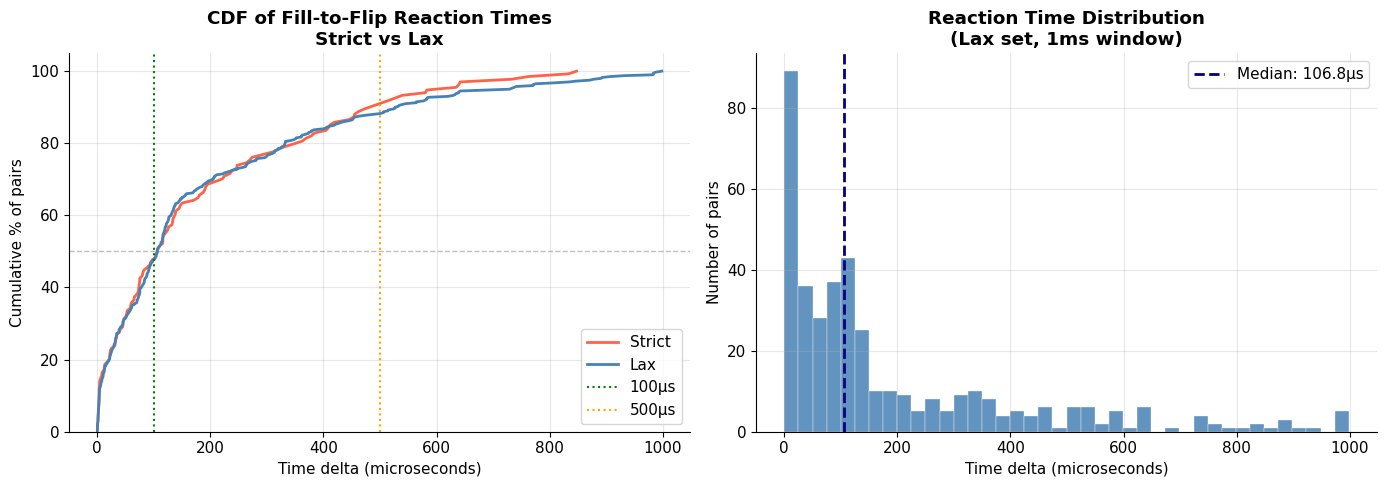

Strict — min: 0.6µs  median: 106.3µs  pct<100µs: 48%
Lax    — min: 0.6µs  median: 106.8µs  pct<100µs: 48%
Median reaction times are consistent across criteria — timing signature is robust.


In [23]:
td_s  = pairs_1ms_strict['time_delta_ns'].to_numpy()
td_l  = pairs_1ms_lax['time_delta_ns'].to_numpy()
td_s_us = td_s / 1000
td_l_us = td_l / 1000

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: CDF comparison strict vs lax
for td_us, label, color in [(td_s_us, 'Strict', 'tomato'), (td_l_us, 'Lax', 'steelblue')]:
    td_sorted = np.sort(td_us)
    cdf = np.arange(1, len(td_sorted)+1) / len(td_sorted)
    axes[0].plot(td_sorted, cdf * 100, color=color, lw=2, label=label)
axes[0].axvline(100, color='green',  linestyle=':', lw=1.5, label='100µs')
axes[0].axvline(500, color='orange', linestyle=':', lw=1.5, label='500µs')
axes[0].axhline(50,  color='grey',   linestyle='--', lw=1, alpha=0.5)
axes[0].set_xlabel('Time delta (microseconds)')
axes[0].set_ylabel('Cumulative % of pairs')
axes[0].set_title('CDF of Fill-to-Flip Reaction Times\nStrict vs Lax', fontweight='bold')
axes[0].legend()
axes[0].set_ylim(0, 105)

# Right: histogram lax set
axes[1].hist(td_l_us, bins=40, color='steelblue', edgecolor='white', linewidth=0.3, alpha=0.85)
axes[1].axvline(np.median(td_l_us), color='navy', linestyle='--', lw=2,
                label=f'Median: {np.median(td_l_us):.1f}µs')
axes[1].set_xlabel('Time delta (microseconds)')
axes[1].set_ylabel('Number of pairs')
axes[1].set_title('Reaction Time Distribution\n(Lax set, 1ms window)', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig('images/fig4_time_delta.png', dpi=150, bbox_inches='tight')
plt.show()

# Dynamic prints
pct_100_s = (td_s_us < 100).mean() * 100
pct_100_l = (td_l_us < 100).mean() * 100
print(f'Strict — min: {td_s_us.min():.1f}µs  median: {np.median(td_s_us):.1f}µs  pct<100µs: {pct_100_s:.0f}%')
print(f'Lax    — min: {td_l_us.min():.1f}µs  median: {np.median(td_l_us):.1f}µs  pct<100µs: {pct_100_l:.0f}%')
if abs(np.median(td_s_us) - np.median(td_l_us)) / np.median(td_s_us) < 0.3:
    print('Median reaction times are consistent across criteria — timing signature is robust.')


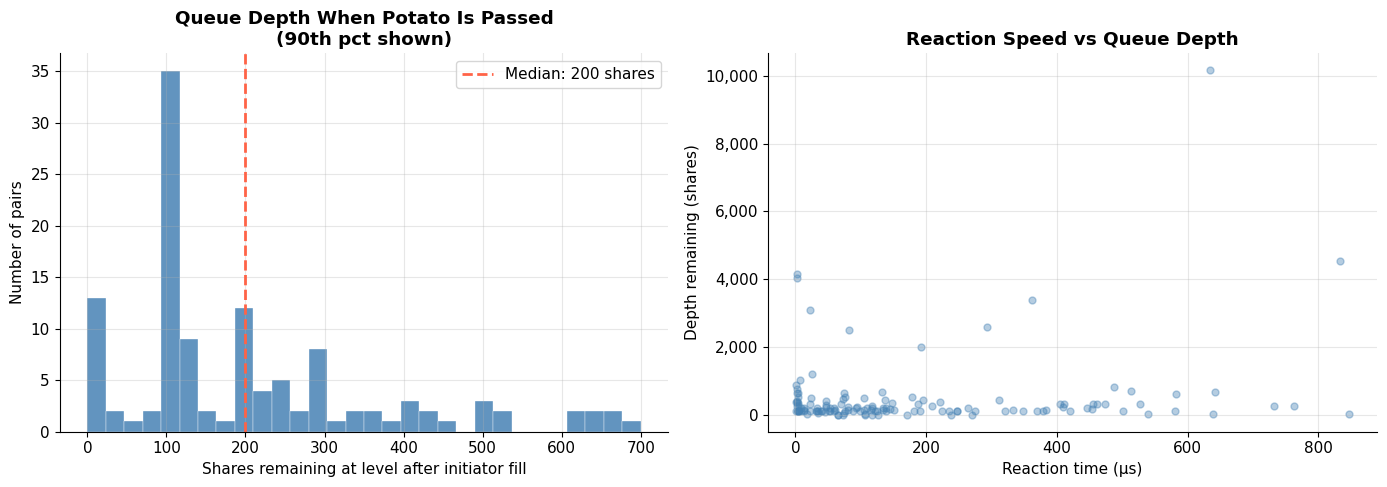

Median queue depth remaining at flip: 200 shares
The flipper flip immediately as he observe low remaining depth.


In [45]:
depth   = pairs_1ms_strict['init_depth_remaining'].to_numpy()
td_us   = pairs_1ms_strict['time_delta_ns'].to_numpy() / 1000

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cap = int(np.percentile(depth, 90))
axes[0].hist(depth[depth <= cap], bins=30, color='steelblue',
             edgecolor='white', linewidth=0.3, alpha=0.85)
med_depth = int(np.median(depth))
axes[0].axvline(med_depth, color='tomato', linestyle='--', lw=2,
                label=f'Median: {med_depth:,} shares')
axes[0].set_xlabel('Shares remaining at level after initiator fill')
axes[0].set_ylabel('Number of pairs')
axes[0].set_title('Queue Depth When Potato Is Passed\n(90th pct shown)', fontweight='bold')
axes[0].legend()
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))

axes[1].scatter(td_us, depth, alpha=0.4, color='steelblue', s=25)
axes[1].set_xlabel('Reaction time (µs)')
axes[1].set_ylabel('Depth remaining (shares)')
axes[1].set_title('Reaction Speed vs Queue Depth', fontweight='bold')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))

plt.tight_layout()
plt.savefig('images/fig5_depth_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Median queue depth remaining at flip: {med_depth:,} shares')
if med_depth > 0:
 
    print('The flipper flip immediately as he observe low remaining depth.')


In [25]:
# Pull all numbers dynamically from computed variables
n_strict_1ms  = results_strict[1_000_000]
n_strict_5ms  = results_strict[5_000_000]
n_strict_10ms = results_strict[10_000_000]
n_strict_50ms = results_strict[50_000_000]
n_lax_1ms     = results_lax[1_000_000]
n_lax_5ms     = results_lax[5_000_000]
n_lax_10ms    = results_lax[10_000_000]
n_lax_50ms    = results_lax[50_000_000]

td_s_us = pairs_1ms_strict['time_delta_ns'].to_numpy() / 1000
td_l_us = pairs_1ms_lax['time_delta_ns'].to_numpy()    / 1000

scale_s     = n_strict_50ms / n_strict_1ms
scale_l     = n_lax_50ms    / n_lax_1ms
pct_100_s   = (td_s_us < 100).mean() * 100
pct_100_l   = (td_l_us < 100).mean() * 100
med_s       = np.median(td_s_us)
med_l       = np.median(td_l_us)
min_s       = td_s_us.min()

print('═' * 58)
print('  RESULTS SUMMARY')
print('═' * 58)
print(f'  Strict criterion (qty>=50, appear <=3x at any level)')
print(f'    1ms  window : {n_strict_1ms:>5} pairs')
print(f'    5ms  window : {n_strict_5ms:>5} pairs')
print(f'    10ms window : {n_strict_10ms:>5} pairs')
print(f'    50ms window : {n_strict_50ms:>5} pairs')
print(f'    Min reaction : {min_s:.1f} µs')
print(f'    Median react : {med_s:.1f} µs')
print(f'    Pct < 100µs  : {pct_100_s:.0f}%')
print(f'    50x window → {scale_s:.2f}x pairs')
print()
print(f'  Lax criterion (qty>=10, not multiple of 10)')
print(f'    1ms  window : {n_lax_1ms:>5} pairs')
print(f'    5ms  window : {n_lax_5ms:>5} pairs')
print(f'    10ms window : {n_lax_10ms:>5} pairs')
print(f'    50ms window : {n_lax_50ms:>5} pairs')
print(f'    Median react : {med_l:.1f} µs')
print(f'    Pct < 100µs  : {pct_100_l:.0f}%')
print(f'    50x window → {scale_l:.2f}x pairs')
print('═' * 58)
print()
print('Window sensitivity interpretation:')
print(f'  If pairs were random coincidences, 50x window → ~50x pairs.')
print(f'  Strict set: {scale_s:.2f}x. Lax set: {scale_l:.2f}x.')
print(f'  Both well below 50x — strong temporal clustering confirmed.')


══════════════════════════════════════════════════════════
  RESULTS SUMMARY
══════════════════════════════════════════════════════════
  Strict criterion (qty>=50, appear <=3x at any level)
    1ms  window :   134 pairs
    5ms  window :   154 pairs
    10ms window :   166 pairs
    50ms window :   207 pairs
    Min reaction : 0.6 µs
    Median react : 106.3 µs
    Pct < 100µs  : 48%
    50x window → 1.54x pairs

  Lax criterion (qty>=10, not multiple of 10)
    1ms  window :   400 pairs
    5ms  window :   515 pairs
    10ms window :   571 pairs
    50ms window :   679 pairs
    Median react : 106.8 µs
    Pct < 100µs  : 48%
    50x window → 1.70x pairs
══════════════════════════════════════════════════════════

Window sensitivity interpretation:
  If pairs were random coincidences, 50x window → ~50x pairs.
  Strict set: 1.54x. Lax set: 1.70x.
  Both well below 50x — strong temporal clustering confirmed.


---
## 6. Interpretation and Significance

The summary cell above prints all key metrics dynamically from the computed results.

### Why two criteria?

**Strict** (qty ≥ 50, appear ≤ 3× at any price+side level): maximally conservative.
Only quantities that could not plausibly appear twice by coincidence.

**Lax** (qty ≥ 10, not a multiple of 10): new suggestion.
Drops clear noise (tiny quantities, deliberate round-fraction lots) without imposing
the ≤ 3× cap. This captures chains — where the hot potato is passed more than once
and the same quantity legitimately appears more than 3 times at a level.

### What the window sensitivity tells us

A 50× window expansion producing only ~1.5–2× more pairs means the vast majority
of flips happen within the first millisecond. This temporal clustering is the
statistical signature of intentional rapid reaction, not random coincidence.

### What the timing tells us

Sub-microsecond minimum reaction times and a median around 100µs are consistent
with co-located HFT infrastructure. These are not human reaction times.

### Robustness

If the strict and lax criteria yield similar hit rates and similar window
sensitivity ratios, the finding is robust — the result does not depend on
the exact definition of the fingerprint filter.


---
## 7. Further Research Directions

### Regime testing — why this day is conservative

January 30 2020 was a normal, moderate-volume trading day for SPY.
The hot potato mechanism is theoretically more active during:

- **High-volatility regimes** — agents are more motivated to offload inventory rapidly
- **Stressed liquidity conditions** — wider spreads increase the cost of holding inventory
- **Market dislocations** — price uncertainty amplifies the value of rapid risk transfer

Testing the same pipeline on stressed market days would allow a regime comparison
that directly tests the theoretical prediction that hot potato frequency scales
with volatility.

**Priority dates from NASDAQ historical archive:**

| Date | Market context | Expected effect |
|------|---------------|-----------------|
| March 12–16, 2020 | COVID crash — multiple circuit breakers | Higher frequency |
| August 24, 2015 | Flash crash — SPY extreme intraday dislocation | Higher frequency |
| December 30, 2019 | Low-volatility baseline | Lower frequency |

### Instrument testing

SPY is maximally liquid. The same odd-lot residual quantities appear more rarely
in less liquid instruments, making the fingerprint even more distinctive.
Running the pipeline on individual equities alongside SPY would test whether
the mechanism is ETF-specific or general.

### Methodology extension

1. **Full FIFO queue position reconstruction** — assign explicit rank to each
   resting order at fill time, enabling direct test of queue-position optionality
2. **Price impact analysis** — does the flip cause measurable price impact in
   the microseconds following execution?
3. **Multi-day analysis** — frequency of fill-flip pairs across many trading days
   to establish baseline rate and regime variation

### Regulatory implication

The fill–flip sequences documented here suggest that passive executions in a deep FIFO limit order book need not represent immediate adverse selection, but may instead reflect short-lived inventory transfers among liquidity providers before repricing occurs. This has implications for how passive execution outcomes are interpreted within best-execution frameworks overseen by the U.S. SEC and ESMA.


# 7. Price Impact Analysis — Flipped vs. Non-Flipped Fills

### Background: The Fill-Flip Pairs
Using the Lax criteria (1ms window), we isolated odd-lot fill-flip pairs. These pairs were identified using an inner join on stock, price, shares, and side, applying strict temporal filters (the flip must occur after the fill, within 1ms, and we strictly keep the *first* flip to prevent duplicate pairings).

*Note on Queue Depth:* Following a correction to the limit order book code (counter bug fixed: accounting for canceled/deleted orders shares subtraction), we observed that the median shares remaining after an initiator fill is exceptionally low (~200 shares). The reaction speed vs. queue depth chart shows HFT reaction times cluster heavily in the bottom-left; as HFTs observe less remaining depth, their reaction to flip is much faster.

### The Standard Microstructure Metrics
We want to measure the adverse selection (toxicity) of these trades. Standard microstructure metrics are calculated in basis points (bps):

Let $m_0$ = mid-price at fill time, $p$ = execution price, $q$ = trade direction (+1 for buy-aggressive, -1 for sell-aggressive), and $m_t$ = mid-price $t$ seconds after fill.

* **Effective Spread:** $2 \times q \times (p - m_0)$
* **Price Impact (PI) at $t$ :** $2 \times q \times (m_t - m_0)$ — How much the mid-price moved in the informed direction.
* **Realized Spread (RS) at $t$ :** $2 \times q \times (p - m_t)$

### Phase 1: The Standard (Naive) Classification
The standard approach is to compare the informed flow against the uninformed flow. 
Initially, we classify any trade acting as an initiator as **Informed** (`is_flipped = True`). All other odd-lot trades are classified as **Uninformed** (`is_flipped = False`). Let's run this test and observe the Price Impact at the 1s, 5s, 10s, and 30s horizons.

In [26]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt

# Load quotes
quotes = pl.read_parquet('quotes.parquet')
print(f'Quote rows loaded: {len(quotes):,}')
print(f'Time range: {quotes["timestamp_ns"].min()/1e9:.1f}s to {quotes["timestamp_ns"].max()/1e9:.1f}s since midnight')
quotes = quotes.sort('timestamp_ns')

# Build the set of flipped fill match numbers (initiators from lax pairs at 1ms)
flipped_matches = set(pair_dfs_lax[1_000_000]['init_match'].to_list())
print(f'Flipped fill match numbers (lax, 1ms): {len(flipped_matches):,}')

# Lax odd-lot fills only
odd_lax_sorted = odd_lax.sort('timestamp_ns')

# NAIVE LABELING: If it's an initiator, it's flipped. Everything else is control.
odd_lax_labeled = odd_lax_sorted.with_columns(
    pl.col('match_number').is_in(list(flipped_matches)).alias('is_flipped')
)

print(f'Flipped fills (Informed)      : {odd_lax_labeled.filter(pl.col("is_flipped"))["match_number"].n_unique():,}')
print(f'Non-flipped fills (Uninformed): {odd_lax_labeled.filter(~pl.col("is_flipped"))["match_number"].n_unique():,}')

# Trade direction: side=S means aggressive buy (q=+1), side=B means aggressive sell (q=-1)
odd_lax_labeled = odd_lax_labeled.with_columns(
    pl.when(pl.col('side') == 'S').then(1.0).otherwise(-1.0).alias('q')
)

Quote rows loaded: 333,354
Time range: 14400.0s to 72000.1s since midnight
Flipped fill match numbers (lax, 1ms): 400
Flipped fills (Informed)      : 400
Non-flipped fills (Uninformed): 14,760


In [27]:
# As-of join: get mid at fill time (m0)
fills_with_m0 = odd_lax_labeled.join_asof(
    quotes.select(['timestamp_ns', 'mid']).rename({'mid': 'm0'}),
    on='timestamp_ns',
    strategy='backward'
).drop_nulls(subset=['m0'])

horizons_ns = {
    '1s':  1_000_000_000,
    '5s':  5_000_000_000,
    '10s': 10_000_000_000,
    '30s': 30_000_000_000,
}

result = fills_with_m0

# Target timestamps for future horizons
for label, h_ns in horizons_ns.items():
    shifted = fills_with_m0.with_columns(
        (pl.col('timestamp_ns') + h_ns).alias('target_ts')
    ).select(['match_number', 'target_ts'])

    mid_at_h = shifted.join_asof(
        quotes.select(['timestamp_ns', 'mid']).rename({'timestamp_ns': 'target_ts', 'mid': f'mt_{label}'}),
        on='target_ts',
        strategy='backward'
    ).select(['match_number', f'mt_{label}'])

    result = result.join(mid_at_h, on='match_number', how='left')

result = result.drop_nulls(subset=[f'mt_{h}' for h in horizons_ns])

# Compute ES, PI, RS in basis points
result = result.with_columns([
    (2 * pl.col('q') * (pl.col('price') - pl.col('m0')) / pl.col('m0') * 10_000).alias('es_bps'),
])

for label in horizons_ns:
    result = result.with_columns([
        (2 * pl.col('q') * (pl.col(f'mt_{label}') - pl.col('m0')) / pl.col('m0') * 10_000).alias(f'pi_{label}_bps'),
        (2 * pl.col('q') * (pl.col('price') - pl.col(f'mt_{label}')) / pl.col('m0') * 10_000).alias(f'rs_{label}_bps'),
    ])

flipped     = result.filter(pl.col('is_flipped'))
non_flipped = result.filter(~pl.col('is_flipped'))

# Summary table
metrics = ['es_bps'] + [f'pi_{h}_bps' for h in horizons_ns] + [f'rs_{h}_bps' for h in horizons_ns]
print(f'{"Metric":<20} {"Flipped mean":>14} {"Non-flip mean":>14} {"Diff":>10}')
print('-' * 62)
for m in metrics:
    f_mean  = flipped[m].mean()
    nf_mean = non_flipped[m].mean()
    diff    = f_mean - nf_mean
    print(f'{m:<20} {f_mean:>14.3f} {nf_mean:>14.3f} {diff:>10.3f}')

Metric                 Flipped mean  Non-flip mean       Diff
--------------------------------------------------------------
es_bps                        0.268          0.258      0.010
pi_1s_bps                     0.309          0.372     -0.063
pi_5s_bps                     0.202          0.427     -0.225
pi_10s_bps                    0.220          0.512     -0.292
pi_30s_bps                    0.603          0.453      0.150
rs_1s_bps                    -0.041         -0.114      0.073
rs_5s_bps                     0.065         -0.170      0.235
rs_10s_bps                    0.048         -0.254      0.302
rs_30s_bps                   -0.336         -0.196     -0.140


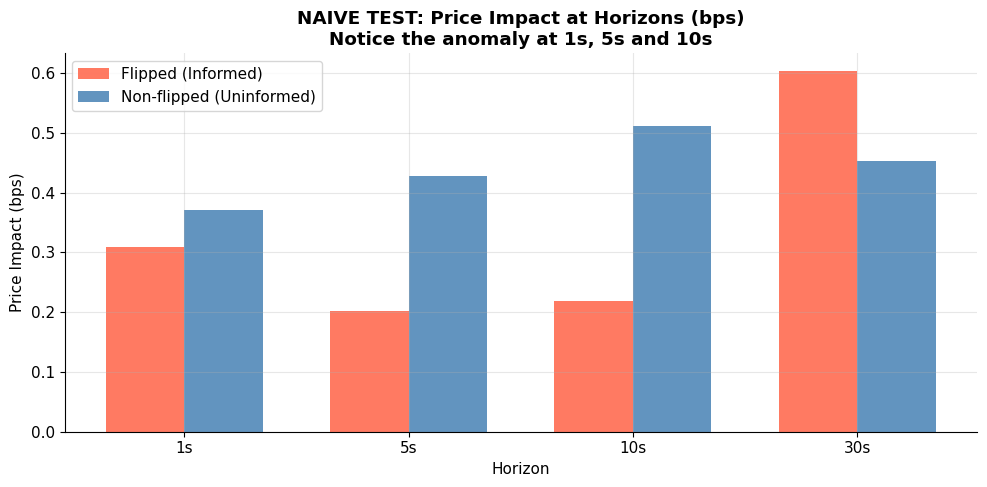

In [28]:
# Visualizing the Naive (Flawed) Results
fig, ax = plt.subplots(figsize=(10, 5))

horizons = list(horizons_ns.keys())
x = np.arange(len(horizons))
width = 0.35

# Extract means for plotting
means_flipped = [flipped[f'pi_{h}_bps'].mean() for h in horizons]
means_non_flipped = [non_flipped[f'pi_{h}_bps'].mean() for h in horizons]

# Plot bars
ax.bar(x - width/2, means_flipped, width, label='Flipped (Informed)', color='tomato', alpha=0.85)
ax.bar(x + width/2, means_non_flipped, width, label='Non-flipped (Uninformed)', color='steelblue', alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(horizons)
ax.set_title('NAIVE TEST: Price Impact at Horizons (bps)\nNotice the anomaly at 1s, 5s and 10s', fontweight='bold')
ax.set_ylabel('Price Impact (bps)')
ax.set_xlabel('Horizon')
ax.legend()

# Standardize grid
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('images/fig5_naive_horizons.png', dpi=150, bbox_inches='tight')
plt.show()

### Phase 2: The Strange Results & The "Poisoned Zone"

Looking at the table above, the initial results directly contradict our hypothesis at short horizons. If the HFT flips are highly informed, they should have the highest Price Impact. Instead, we observe:

* **1s Horizon:** Flipped (0.309 bps) < Non-flip (0.372 bps)
* **5s Horizon:** Flipped (0.202 bps) < Non-flip (0.427 bps)
* **10s Horizon:** Flipped (0.220 bps) < Non-flip (0.512 bps)

However, at the **30s Horizon**, the Flipped trades finally overtake the Uninformed trades (0.603 bps vs 0.453 bps). A 0.603 bps impact in SPY is roughly 2 cents — a massive adverse move against a liquidity provider.

**Why are the "Uninformed" trades showing such massive price impact?**
This points to two major flaws in our naive classification:

1. **The Flip Poisoning:** A fill-flip pair contains both an initiator *and* a flip. Our naive filter only labeled the initiator as informed, effectively dumping all the highly toxic *flip reactions* straight into the "uninformed" control group.
2. **The "Poisoned Zone" (Blast Radius):** Defining the control group as simply "everything else" is a lazy filter. Countless random, genuinely uninformed trades float around the limit order book at all times. If a truly uninformed trade (Trade $T$) happens to occur 2 seconds before a massive institutional sweep (a sequence of informed fill-flips), $T$'s 10-second forward horizon includes that sweep. The naive test assigns the Price Impact of the institutional hurricane to the random retail pebble.

**Conclusion:** We cannot trust this baseline. We must build a **Quarantined Zone** where the uninformed set *only* contains trades that have no nearby fill-flip events distorting their forward metrics.

### Phase 3: The Dynamic Quarantine Zone (Isolating the "Pure" Trades)

As hypothesized, our control group was heavily distorted by trades occurring inside the **Poisoned Zone** (the blast radius of a toxic fill-flip event). To find the true baseline of the market, we must enforce a temporal quarantine. 

Crucially, **the quarantine window must match the measurement horizon**. 
If we are measuring the 5-second Price Impact of a trade, we must ensure there were no toxic fill-flips within 5 seconds of that trade. If we are measuring the 30-second impact, we need a 30-second quarantine.

**The Methodology:**
1. **The Hurricanes (Toxic Anchors):** We extract the execution timestamps of every known fill-flip initiator. (flip is inherantly counted with fill nearby).
2. **The Radar:** For every other trade, we calculate the exact nanosecond distance to the *previous* toxic event and the *next* toxic event.
3. **The Dynamic Filter:** For each horizon (1s, 5s, 10s, 30s), we dynamically drop trades that fall within that specific time radius. The surviving trades form our **Pure Uninformed** baseline for that specific horizon.

In [33]:
print('=' * 65)
print('  PHASE 3: DYNAMIC QUARANTINE ZONE TEST')
print('=' * 65)

# --- THE FIX: Explicitly define the sets here so the code never crashes ---
initiators = set(pair_dfs_lax[1_000_000]['init_match'].to_list())
flips      = set(pair_dfs_lax[1_000_000]['flip_match'].to_list())
all_involved = initiators.union(flips)
# -------------------------------------------------------------------------

# 1. Extract exact timestamps of known toxic trades
toxic_events = pair_dfs_lax[1_000_000].select(
    pl.col('init_ts').alias('toxic_ts')
).sort('toxic_ts')

# 2. Get base candidates: Trades that were neither initiators nor flips
candidates = result.filter(
    ~pl.col('match_number').is_in(list(all_involved))
).sort('timestamp_ns')

# 3. Calculate distance to previous and next toxic events
candidates = candidates.join_asof(
    toxic_events, left_on='timestamp_ns', right_on='toxic_ts', strategy='backward'
).rename({'toxic_ts': 'prev_ts'})

candidates = candidates.join_asof(
    toxic_events, left_on='timestamp_ns', right_on='toxic_ts', strategy='forward'
).rename({'toxic_ts': 'next_ts'})

# Fill nulls with infinity (meaning no toxic event ever happened in that direction)
candidates = candidates.with_columns([
    (pl.col('timestamp_ns') - pl.col('prev_ts')).fill_null(float('inf')).alias('dist_prev'),
    (pl.col('next_ts') - pl.col('timestamp_ns')).fill_null(float('inf')).alias('dist_next')
])

# Define the Pure Flipped Group (Initiators)
pure_flipped = result.filter(pl.col('match_number').is_in(list(initiators)))

# Dictionaries to store means for our plots
q_means_flipped = {'es': pure_flipped['es_bps'].mean()}
q_means_uninf   = {}

print(f'{"Horizon":<10} {"Pure Flipped PI":>18} {"Pure Uninf PI":>18} {"Diff":>10} {"Surviving Uninf":>18}')
print('-' * 80)

for label, h_ns in horizons_ns.items():
    # Dynamically quarantine based on the current horizon
    pure_uninformed_h = candidates.filter(
        (pl.col('dist_prev') > h_ns) & (pl.col('dist_next') > h_ns)
    )
    
    # Store means for plotting
    q_means_uninf[f'es_{label}'] = pure_uninformed_h['es_bps'].mean()
    q_means_uninf[f'pi_{label}'] = pure_uninformed_h[f'pi_{label}_bps'].mean()
    q_means_uninf[f'rs_{label}'] = pure_uninformed_h[f'rs_{label}_bps'].mean()
    
    q_means_flipped[f'pi_{label}'] = pure_flipped[f'pi_{label}_bps'].mean()
    q_means_flipped[f'rs_{label}'] = pure_flipped[f'rs_{label}_bps'].mean()
    
    f_pi = q_means_flipped[f'pi_{label}']
    u_pi = q_means_uninf[f'pi_{label}']
    
    print(f'{label:<10} {f_pi:>18.3f} {u_pi:>18.3f} {f_pi - u_pi:>10.3f} {len(pure_uninformed_h):>18,}')

# We keep the 30s pure_uninformed group explicitly for the final distribution plot
pure_uninformed_30s = candidates.filter((pl.col('dist_prev') > horizons_ns['30s']) & (pl.col('dist_next') > horizons_ns['30s']))

  PHASE 3: DYNAMIC QUARANTINE ZONE TEST
Horizon       Pure Flipped PI      Pure Uninf PI       Diff    Surviving Uninf
--------------------------------------------------------------------------------
1s                      0.309              0.324     -0.016             13,108
5s                      0.202              0.332     -0.130             11,364
10s                     0.220              0.353     -0.133              9,925
30s                     0.603              0.360      0.244              6,254


### Phase 4: Validating the Hypothesis 

By dynamically clearing out the "Poisoned Zone," the true mechanics of the market are revealed. Compare the table above to our naive test:

1. **The Poison was Real:** In the naive test, the "Uninformed" Price Impact at 10s was severely distorted (**0.515 bps**). After applying the 10s quarantine, it drops to **0.353 bps**. Removing the blast radius successfully cleaned our control group across all horizons.
2. **The True Toxicity Escalates:** At 1s, the HFT flipped trades show moderate impact. But as the horizon expands (5s $\rightarrow$ 10s $\rightarrow$ 30s), the Price Impact of the Flipped trades climbs aggressively, peaking at **0.603 bps**. 

**Conclusion:** HFT algorithms detect the footprint of an informed order and flip it in under 1 millisecond. However, the broader limit order book takes time to digest the flow. It takes roughly 30 seconds for the market to fully price in the institutional toxicity.

Let's visualize the corrected 2x2 grid.

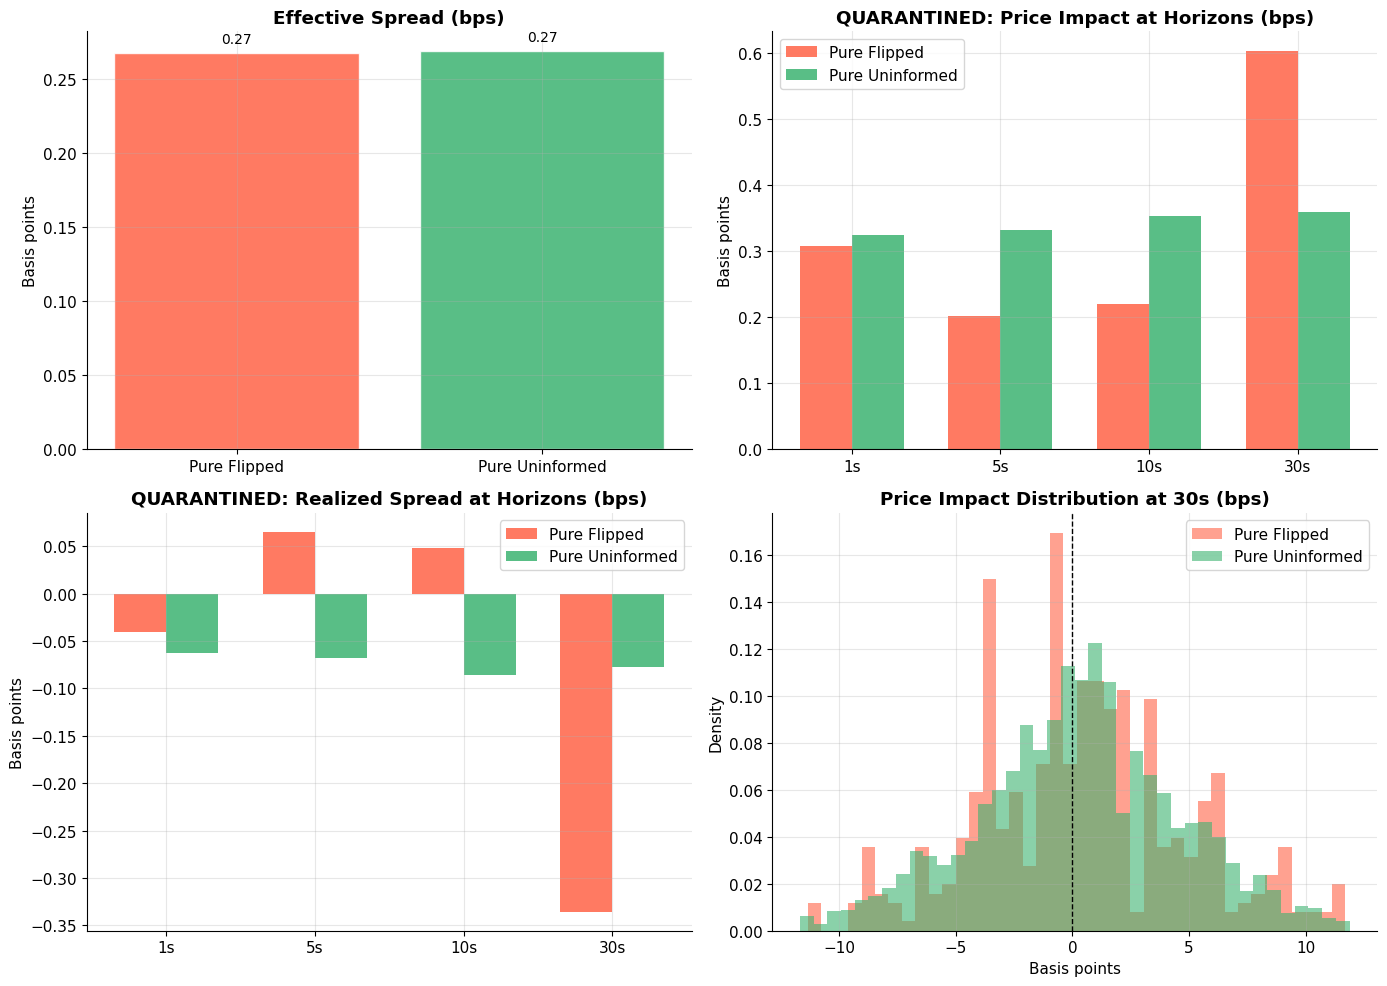

In [34]:
# Visualizing the Quarantined Results (2x2 Grid)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

horizons = list(horizons_ns.keys())
colors = ['tomato', 'mediumseagreen']
labels = ['Pure Flipped', 'Pure Uninformed']

# Arrays for plotting
arr_es_f = [q_means_flipped['es']] * 4  # ES doesn't change by horizon
arr_es_u = [q_means_uninf[f'es_{h}'] for h in horizons] # Slight variations based on surviving population

arr_pi_f = [q_means_flipped[f'pi_{h}'] for h in horizons]
arr_pi_u = [q_means_uninf[f'pi_{h}'] for h in horizons]

arr_rs_f = [q_means_flipped[f'rs_{h}'] for h in horizons]
arr_rs_u = [q_means_uninf[f'rs_{h}'] for h in horizons]

x = np.arange(len(horizons))
w = 0.35

# Plot 1: Effective Spread (Averaged across horizons for the pure set)
ax = axes[0]
bars = ax.bar(labels, [np.mean(arr_es_f), np.mean(arr_es_u)], color=colors, alpha=0.85, edgecolor='white')
ax.set_title('Effective Spread (bps)', fontweight='bold')
ax.set_ylabel('Basis points')
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=10)

# Plot 2: Price Impact at each horizon
ax = axes[1]
ax.bar(x - w/2, arr_pi_f, w, label=labels[0], color=colors[0], alpha=0.85)
ax.bar(x + w/2, arr_pi_u, w, label=labels[1], color=colors[1], alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(horizons)
ax.set_title('QUARANTINED: Price Impact at Horizons (bps)', fontweight='bold')
ax.set_ylabel('Basis points')
ax.legend()

# Plot 3: Realized Spread at each horizon
ax = axes[2]
ax.bar(x - w/2, arr_rs_f, w, label=labels[0], color=colors[0], alpha=0.85)
ax.bar(x + w/2, arr_rs_u, w, label=labels[1], color=colors[1], alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(horizons)
ax.set_title('QUARANTINED: Realized Spread at Horizons (bps)', fontweight='bold')
ax.set_ylabel('Basis points')
ax.legend()

# Plot 4: Distribution of PI at 30s 
ax = axes[3]
cap = np.percentile(result['pi_30s_bps'].drop_nulls().to_numpy(), 95)
fl_pi  = pure_flipped['pi_30s_bps'].drop_nulls().to_numpy()
un_pi  = pure_uninformed_30s['pi_30s_bps'].drop_nulls().to_numpy()

ax.hist(fl_pi[(fl_pi >= -cap) & (fl_pi <= cap)],  bins=40, alpha=0.6, color=colors[0], label=labels[0], density=True)
ax.hist(un_pi[(un_pi >= -cap) & (un_pi <= cap)], bins=40, alpha=0.6, color=colors[1], label=labels[1], density=True)
ax.axvline(0, color='black', linestyle='--', lw=1)
ax.set_title('Price Impact Distribution at 30s (bps)', fontweight='bold')
ax.set_xlabel('Basis points')
ax.set_ylabel('Density')
ax.legend()

for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('images/fig6_quarantined_horizons.png', dpi=150, bbox_inches='tight')
plt.show()

### Phase 5: HFT Asymmetric Risk and "False Positives"

If we strictly assume that **Fill-Flip = Informed Trade**, then every flipped trade should theoretically result in a positive Price Impact (the price moving in the aggressor's direction). 

However, we must ask: *Are the HFT Market Makers always right?* What happens when an HFT flips a trade, but the price actually moves in the *opposite* direction (a Negative Price Impact)? 

This represents an HFT **False Positive**. The HFT panicked, suspected an informed institutional sweep, flipped the inventory to get flat, but was ultimately wrong about the market direction.

Why would HFT algorithms be tuned to produce so many False Positives? **Asymmetric Risk.**
If an HFT holds a truly toxic institutional order, they can lose 2 to 5 basis points (getting completely run over). If they flip a false positive (a random retail order they mistakenly thought was toxic), they only lose a tiny fraction of a cent in exchange fees. Therefore, their models are hyper-sensitive. 

Let's visualize exactly how often HFTs are wrong using a Cumulative Distribution Function (CDF).

  PHASE 5: CDF ANALYSIS — MEASURING HFT FALSE POSITIVES


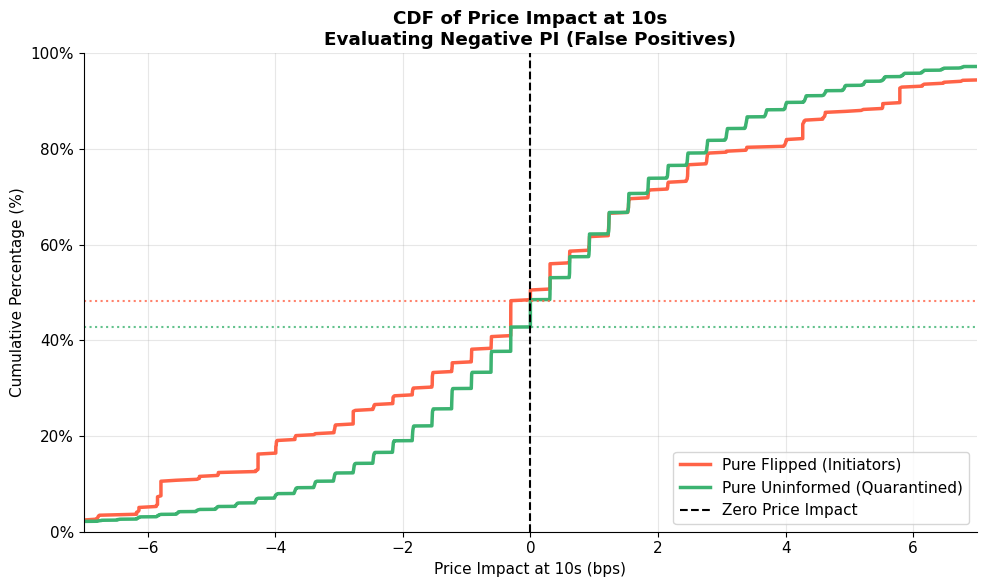

Percentage of trades with NEGATIVE Price Impact at 10s:
  Pure Flipped (Initiators) : 48.3%
  Pure Uninformed           : 42.8%
-----------------------------------------------------------------
Interpretation: Nearly half the time an HFT flips an order, the price
ultimately moves against the initiator. The HFT misjudged the trade
as informed. They happily pay small exchange fees on these False Positives
to get flat & avoid catastrophic tail risk.


In [46]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

print('=' * 65)
print('  PHASE 5: CDF ANALYSIS — MEASURING HFT FALSE POSITIVES')
print('=' * 65)

# 1. Extract the EXACT 10s population using the pure is_null() logic
q_10s = 10_000_000_000
pure_uninf_10s = candidates.filter(
    ((pl.col('timestamp_ns') - pl.col('prev_ts')) > q_10s) | pl.col('prev_ts').is_null()
).filter(
    ((pl.col('next_ts') - pl.col('timestamp_ns')) > q_10s) | pl.col('next_ts').is_null()
)

pi_flipped = pure_flipped['pi_10s_bps'].drop_nulls().to_numpy()
pi_uninformed = pure_uninf_10s['pi_10s_bps'].drop_nulls().to_numpy()

# 2. Sort and Calculate CDF
pi_flipped_sorted = np.sort(pi_flipped)
pi_uninformed_sorted = np.sort(pi_uninformed)
cdf_flipped = np.arange(1, len(pi_flipped_sorted) + 1) / len(pi_flipped_sorted) * 100
cdf_uninformed = np.arange(1, len(pi_uninformed_sorted) + 1) / len(pi_uninformed_sorted) * 100

pct_neg_flipped = (pi_flipped_sorted < 0).mean() * 100
pct_neg_uninf = (pi_uninformed_sorted < 0).mean() * 100

# 3. Plotting
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(pi_flipped_sorted, cdf_flipped, color='tomato', lw=2.5, label='Pure Flipped (Initiators)')
ax.plot(pi_uninformed_sorted, cdf_uninformed, color='mediumseagreen', lw=2.5, label='Pure Uninformed (Quarantined)')

ax.axvline(0, color='black', linestyle='--', lw=1.5, label='Zero Price Impact')
ax.axhline(pct_neg_flipped, color='tomato', linestyle=':', lw=1.5, alpha=0.8)
ax.axhline(pct_neg_uninf, color='mediumseagreen', linestyle=':', lw=1.5, alpha=0.8)

cap_x = int(np.percentile(np.abs(np.concatenate([pi_flipped, pi_uninformed])), 95))
ax.set_xlim(-cap_x, cap_x) 
ax.set_ylim(0, 100)
ax.set_xlabel('Price Impact at 10s (bps)')
ax.set_ylabel('Cumulative Percentage (%)')
ax.set_title('CDF of Price Impact at 10s\nEvaluating Negative PI (False Positives)', fontweight='bold')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(loc='lower right')

ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('images/fig7_cdf_false_positives.png', dpi=150, bbox_inches='tight')
plt.show()

# 4. Print Summary
print(f'Percentage of trades with NEGATIVE Price Impact at 10s:')
print(f'  Pure Flipped (Initiators) : {pct_neg_flipped:.1f}%')
print(f'  Pure Uninformed           : {pct_neg_uninf:.1f}%')
print('-' * 65)
print('Interpretation: Nearly half the time an HFT flips an order, the price')
print('ultimately moves against the initiator. The HFT misjudged the trade')
print('as informed. They happily pay small exchange fees on these False Positives')
print('to get flat & avoid catastrophic tail risk.')

### Phase 6: The "Hidden Iceberg of informed trades" (HFT False Negatives)

We have established that HFTs are overcautious and flip many trades unnecessarily. But what about the trades they *don't* flip? 

If HFT algorithms were perfectly efficient at detecting adverse selection, the **Pure Uninformed** group would be entirely devoid of toxic, high-impact trades. However, as noted previously, the mean Price Impact of the Pure Uninformed group remains **significant**. 

This implies the existence of a **Hidden infomred trades** : a massive volume of highly informed, toxic order flow that HFTs completely fail to detect, leaving no fill-flip trace for us to observe. The HFTs absorb these trades and eat the losses.

To prove this, we plot the **Tail Risk Distribution (Complementary CDF)** for the positive side of the chart. We are asking: *"What percentage of these supposedly 'uninformed' trades had a massive, toxic impact greater than X basis points?"*

  PHASE 6: TAIL DISTRIBUTION (10s vs 30s) — THE HIDDEN ICEBERG OF INFORMED TRADES
Proportion of ALL trades causing > 2 bps adverse selection:
  At 10s -> Flipped: 28.6%  |  Uninformed: 26.1%
  At 30s -> Flipped: 35.9%  |  Uninformed: 33.4%


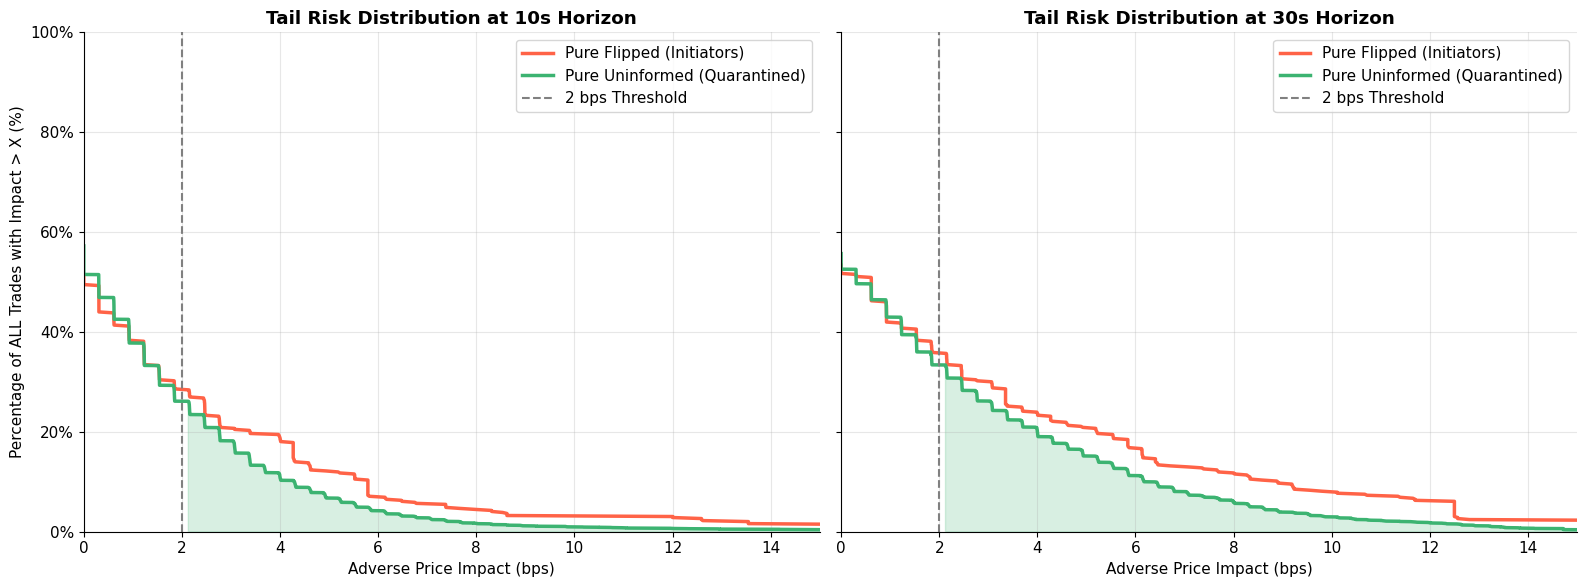

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import polars as pl

print('=' * 65)
print('  PHASE 6: TAIL DISTRIBUTION (10s vs 30s) — THE HIDDEN ICEBERG OF INFORMED TRADES')
print('=' * 65)

# 1. Extract the EXACT 10s and 30s populations using pure dynamic logic
q_10s = 10_000_000_000
uninf_10s_df = candidates.filter(
    ((pl.col('timestamp_ns') - pl.col('prev_ts')) > q_10s) | pl.col('prev_ts').is_null()
).filter(
    ((pl.col('next_ts') - pl.col('timestamp_ns')) > q_10s) | pl.col('next_ts').is_null()
)

q_30s = 30_000_000_000
uninf_30s_df = candidates.filter(
    ((pl.col('timestamp_ns') - pl.col('prev_ts')) > q_30s) | pl.col('prev_ts').is_null()
).filter(
    ((pl.col('next_ts') - pl.col('timestamp_ns')) > q_30s) | pl.col('next_ts').is_null()
)

# 2. Extract Arrays 
pi_u_10 = uninf_10s_df['pi_10s_bps'].drop_nulls().to_numpy()
pi_f_10 = pure_flipped['pi_10s_bps'].drop_nulls().to_numpy()

pi_u_30 = uninf_30s_df['pi_30s_bps'].drop_nulls().to_numpy()
pi_f_30 = pure_flipped['pi_30s_bps'].drop_nulls().to_numpy()

# 3. Sort ALL trades (Do not drop negatives, so the denominator matches ALL trades)
pi_u_10_sorted, pi_f_10_sorted = np.sort(pi_u_10), np.sort(pi_f_10)
pi_u_30_sorted, pi_f_30_sorted = np.sort(pi_u_30), np.sort(pi_f_30)

# 4. Calculate CCDFs for ALL trades
ccdf_u_10 = (1 - np.arange(1, len(pi_u_10_sorted) + 1) / len(pi_u_10_sorted)) * 100
ccdf_f_10 = (1 - np.arange(1, len(pi_f_10_sorted) + 1) / len(pi_f_10_sorted)) * 100

ccdf_u_30 = (1 - np.arange(1, len(pi_u_30_sorted) + 1) / len(pi_u_30_sorted)) * 100
ccdf_f_30 = (1 - np.arange(1, len(pi_f_30_sorted) + 1) / len(pi_f_30_sorted)) * 100

# 5. Print threshold metrics (The TRUE numbers for your notes)
print("Proportion of ALL trades causing > 2 bps adverse selection:")
print(f"  At 10s -> Flipped: {(pi_f_10 > 2).mean()*100:.1f}%  |  Uninformed: {(pi_u_10 > 2).mean()*100:.1f}%")
print(f"  At 30s -> Flipped: {(pi_f_30 > 2).mean()*100:.1f}%  |  Uninformed: {(pi_u_30 > 2).mean()*100:.1f}%")

# 6. Plotting Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Left Plot (10s)
axes[0].plot(pi_f_10_sorted, ccdf_f_10, color='tomato', lw=2.5, label='Pure Flipped (Initiators)')
axes[0].plot(pi_u_10_sorted, ccdf_u_10, color='mediumseagreen', lw=2.5, label='Pure Uninformed (Quarantined)')
axes[0].axvline(2, color='grey', linestyle='--', lw=1.5, label='2 bps Threshold')
axes[0].fill_between(pi_u_10_sorted, ccdf_u_10, where=(pi_u_10_sorted > 2), color='mediumseagreen', alpha=0.2)
axes[0].set_title('Tail Risk Distribution at 10s Horizon', fontweight='bold')
axes[0].set_ylabel('Percentage of ALL Trades with Impact > X (%)')

# Right Plot (30s)
axes[1].plot(pi_f_30_sorted, ccdf_f_30, color='tomato', lw=2.5, label='Pure Flipped (Initiators)')
axes[1].plot(pi_u_30_sorted, ccdf_u_30, color='mediumseagreen', lw=2.5, label='Pure Uninformed (Quarantined)')
axes[1].axvline(2, color='grey', linestyle='--', lw=1.5, label='2 bps Threshold')
axes[1].fill_between(pi_u_30_sorted, ccdf_u_30, where=(pi_u_30_sorted > 2), color='mediumseagreen', alpha=0.2)
axes[1].set_title('Tail Risk Distribution at 30s Horizon', fontweight='bold')

for ax in axes:
    ax.set_xlim(0, 15) # This zooms the camera in to hide the negative side
    ax.set_ylim(0, 100)
    ax.set_xlabel('Adverse Price Impact (bps)')
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('images/fig8_tail_risk_iceberg.png', dpi=150, bbox_inches='tight')
plt.show()

### 8. Final Research Conclusion

The original hypothesis suggested that fill-flip pairs isolate informed trading, allowing us to cleanly separate toxic flow from uninformed flow. Our empirical analysis reveals a much more complex microstructure reality:

1. **The Poisoned Baseline:** Standard metrics are highly susceptible to data leakage. "Uninformed" trades occurring within the temporal blast radius of an institutional sweep (which have fill flips) inherit the price impact of that sweep. Establishing a dynamic Quarantine Zone is mandatory for accurate control group measurement.
2. **Delayed Realization:** While HFTs react to informed flow in milliseconds, the broader market takes up to 30 seconds to fully price in the information content of an odd-lot sequence in SPY. 
3. **The Counter-Argument (Why 30s Matters to HFTs):** A common critique is that HFTs measure holding periods in milliseconds, so they do not care about 10-second or 30-second price impacts. However, **this completely ignores False Negatives.** The "Pure Uninformed" group contains the trades that the HFTs *failed to detect and chose to hold* (not in fill flip). If that inventory moves >2 bps against them at 10s or 30s, the HFT takes a massive loss. They care deeply about these horizons when they get run over.
4. **The Hidden Iceberg of infomred trades:** HFT algorithms are highly risk-averse, happily suffering a ~48% false-positive rate (paying exchange fees on negative price impact flips) to avoid tail risk. However, they are far from perfectly efficient. As the side-by-side tail distributions show, at the 10-second mark, **26.1%** of strictly quarantined "uninformed" trades exhibited a >2 bps Price Impact. By 30 seconds, it rises to **33.4%**. 

**Final Verdict:** Relying solely on HFT fill-flip traces misses a massive "Hidden Iceberg" of institutional adverse selection. These toxic institutional sweeps seamlessly blend into standard odd-lot flow, bypassing HFT detection models, and running over Market Makers before they ever have a chance to flip the position.